# PatchVision-X: training notebook

A compact Vision Transformer trained **from scratch** on CUB-200-2011 (5,394 train / 600 val / 5,794 test images).
All model code lives in the `patchvision/` package next to this notebook; this notebook only configures and starts training.

**PatchVision-X** = GvT's sparse graph attention (Sci. Rep. 2025) + MSCViT's local-feature block and multi-scale attention (arXiv 2501.06040),
realised as *multi-scale graph attention*, plus four small-data regularisers: bounding-box attention loss, EMA weights, flip-consistency loss, box-guided crops.

**Everything is saved under `results/<experiment>/seed<seed>/`**: the step-by-step `train_log.txt`, `steps.csv`, `history.csv`, curves, attention snapshots, checkpoints, test metrics, confusion matrix, calibration plot.

**How to run**
1. Run the first cell with `SMOKE_TEST = True` (2 epochs on synthetic images, a few minutes) to check the whole pipeline on your machine.
2. Set `SMOKE_TEST = False` and run all cells for the real run. Interrupted? Run all again: it resumes from `last.pt`.
3. After code edits in `patchvision/`, restart the kernel.

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # the folder that contains patchvision/

import torch, pandas as pd
from IPython.display import Image as show_image, display

from patchvision.config import PathsConfig, get_experiment, ablation_suite
from patchvision.data import make_synthetic_dataset, load_data_info, build_loaders
from patchvision.experiment import dry_run, run_experiment, run_suite, summarize_results
from patchvision import visualize as viz

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU ONLY - training will be very slow")

torch 2.5.1+cu124 | CUDA: True | NVIDIA GeForce RTX 4090


## 1. Settings

In [2]:
# ================================ USER SETTINGS ================================
SMOKE_TEST       = False         # True: 2 epochs on synthetic data to test the pipeline. Set False for the real run.
EXPERIMENT       = "base"        # any key of ablation_suite(): "full", "base", "arch_x", "full-ema", ...
SEEDS            = [42]          # use [42, 43, 44] for mean +/- std over seeds
NUM_WORKERS      = 6             # data-loading processes (use 0 if you ever hit a multiprocessing error)
STEP_PRINT_EVERY = 21            # 1 = print EVERY training step (the log file always has every step)
RESUME           = True          # continue from last.pt if a run was interrupted

MODEL_OVERRIDES  = {}            # e.g. {"embed_dim": 384, "depth": 6, "heads": 8}
TRAIN_OVERRIDES  = {}            # e.g. {"epochs": 200, "lr": 3e-4, "bbox_weight": 0.2, "early_stop_patience": 40}
# ===============================================================================

PATHS = PathsConfig(root=".")    # DataPreprocessing_Results/, CUB_200_2011/ and results/ are looked up here
if SMOKE_TEST:
    PATHS = make_synthetic_dataset("smoke_data", n_classes=8, n_train=12, n_val=2, n_test=4)
    TRAIN_OVERRIDES = dict(epochs=2, warmup_epochs=1, batch_size=16, snapshot_every=1, clean_eval_every=1,
                           clean_eval_size=16, early_stop_patience=0, weights_every=0)
    NUM_WORKERS = min(NUM_WORKERS, 2)
    print(">>> SMOKE TEST: synthetic data in ./smoke_data, 2 epochs <<<")
print("experiments available:", list(ablation_suite()))
print("results will be written to:", PATHS.results)

experiments available: ['base', 'lfe', 'multiscale', 'arch_x', 'arch_x+bbox', 'arch_x+ema', 'arch_x+cons', 'arch_x+boxcrop', 'full', 'full-lfe', 'full-multiscale', 'full-gate', 'full-bbox', 'full-ema', 'full-cons', 'full-boxcrop']
results will be written to: C:\Users\sam\Downloads\Samruddhi\patchvision-vit-cub200\results


## 2. Data check: augmented images with their bird box (green). The box must stay on the bird.

splits {'train': 5394, 'val': 600, 'test': 5794} | classes 200 | normalisation mean [0.486, 0.499, 0.431]


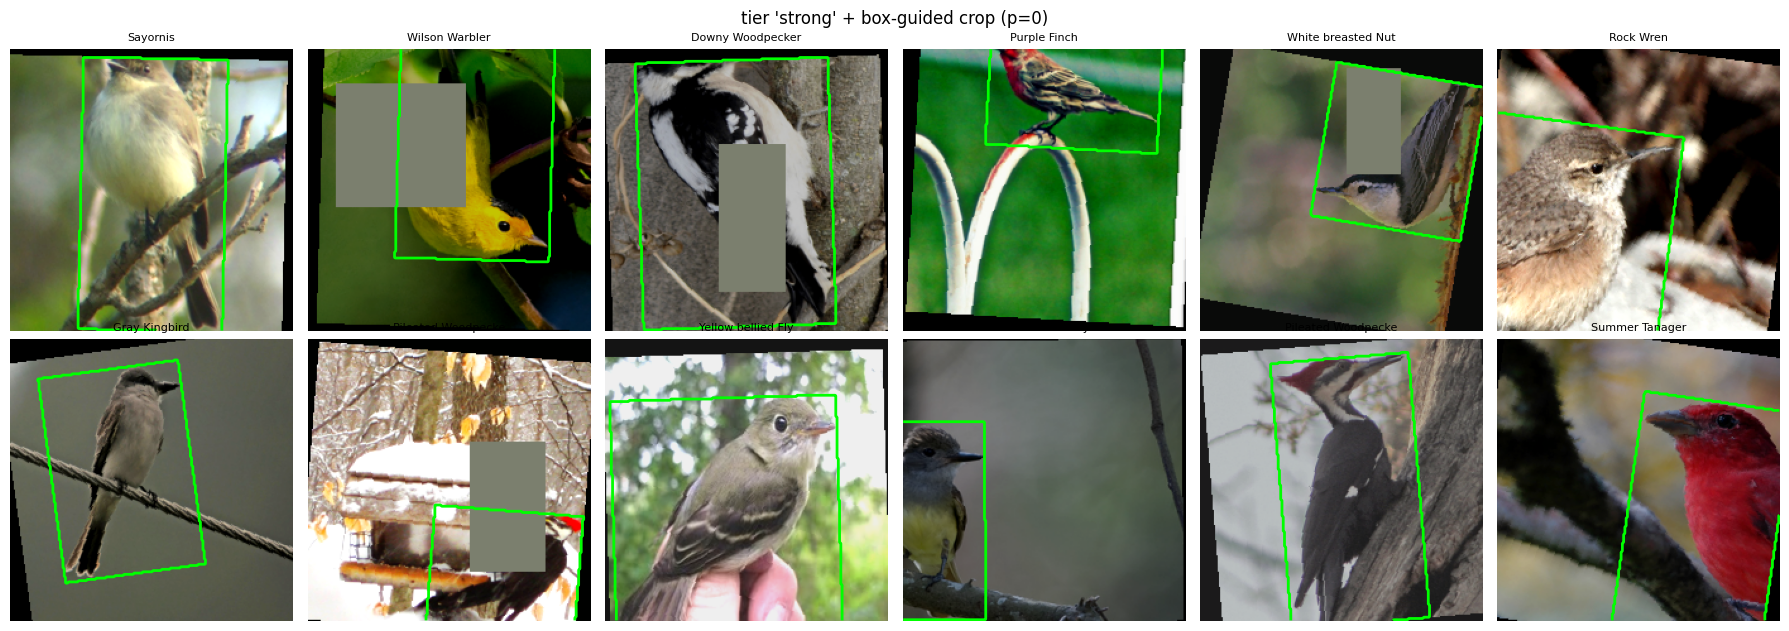

In [3]:
exp = get_experiment(EXPERIMENT, SEEDS[0], MODEL_OVERRIDES, TRAIN_OVERRIDES)
info = load_data_info(PATHS)
print(f"splits {info.splits} | classes {info.num_classes} | normalisation mean {[round(m,3) for m in info.mean]}")
ds, _ = build_loaders(info, exp.train, exp.seed, num_workers=0, pin_memory=False)
(PATHS.results / "_checks").mkdir(parents=True, exist_ok=True)
viz.augmentation_preview(ds["train"], info.mean, info.std, PATHS.results / "_checks" / "augmentation_check.png",
                         n=12, show=True, title=f"tier '{exp.train.aug_tier}' + box-guided crop (p={exp.train.box_crop_prob if exp.train.use_box_crop else 0})")

## 3. Dry run: parameters, FLOPs, one real batch forward/backward, gradient check

In [4]:
report = dry_run(exp, PATHS)

base: 4.31 M parameters | GFLOPs 1.55 | latency bs1 25.2 ms


batch: images (64, 3, 224, 224) | mask max 1.00 (must be 1.0 when boxes are loaded) | x mean/std -0.17/1.11


[1 view] logits (64, 200) | attention maps 4 x (64, 196) | loss 5.3415 (ce 5.3415, chance ln(200) = 5.2983, bbox 0.9494, cons 0.0000/0.0000) | params without finite grad: none [OK]


## 4. Train

Every step prints one line: loss split into CE / bbox / consistency, accuracy, attention-inside-box, learning rate, gradient norm, gate sparsity, images/s, GPU memory, ETA.
After every epoch you get TRAIN / VAL / **CLEAN** (train images without augmentation, the honest overfitting gauge) / ATTN / TIME / BEST.

In [5]:
rows = []
for seed in SEEDS:
    print(f"\n######################## {EXPERIMENT} | seed {seed} ########################")
    run_exp = get_experiment(EXPERIMENT, seed, MODEL_OVERRIDES, TRAIN_OVERRIDES)
    rows.append(run_experiment(run_exp, PATHS, num_workers=NUM_WORKERS,
                               step_print_every=STEP_PRINT_EVERY, resume=RESUME))
results = pd.DataFrame(rows)
results


######################## base | seed 42 ########################


RUN base | seed 42 | device cuda | AMP True (torch.bfloat16)


model  4.31 M params | ModelConfig(img_size=224, num_classes=200, embed_dim=256, depth=8, heads=8, mlp_ratio=3.0, drop=0.0, attn_drop=0.0, drop_path=0.1, tok_groups=4, pool_after=None, pool_ratio=4, adj_mode='hadamard', use_sparse_gate=True, use_lfe=False, keep_abs_pos=False, use_multiscale=False, scales=(1, 2, 4, 0))


train  TrainConfig(epochs=300, batch_size=64, lr=0.0005, min_lr=1e-06, warmup_epochs=10, weight_decay=0.05, betas=(0.9, 0.999), grad_clip=1.0, label_smoothing=0.1, amp=True, aug_tier='strong', use_mixup_cutmix=True, use_bbox_loss=False, bbox_weight=0.1, use_ema=False, ema_decay=0.999, use_consistency=False, cons_logit_weight=1.0, cons_attn_weight=1.0, use_box_crop=False, box_crop_prob=0.3, box_crop_margin=(0.1, 0.4), best_metric='acc1', early_stop_patience=60, early_stop_start=30, clean_eval_every=5, clean_eval_size=600, snapshot_every=10, weights_every=50, plot_every=10)


data   splits {'train': 5394, 'val': 600, 'test': 5794} | classes 200 | steps/epoch 84 | total steps 25,200


...

worst 10 classes (F1):
 class_id             class_name  precision    recall        f1  support
       38       Least Flycatcher   0.000000  0.000000  0.000000       29
      101     Western Wood Pewee   4.761905  3.333333  3.921569       30
       28          American Crow   6.060606  6.666667  6.349206       30
      141             Black Tern   8.333333  6.666667  7.407407       30
      116   Clay colored Sparrow   8.333333  6.896552  7.547170       29
      172 Orange crowned Warbler  14.285714  6.666667  9.090909       30
       90            Mockingbird  15.384615  6.666667  9.302326       30
      134           Bank Swallow   7.547170 13.333333  9.638554       30
       29              Fish Crow  10.000000 10.000000 10.000000       30
       61           Herring Gull  11.538462 10.000000 10.714286       30


best 10 classes (F1):
 class_id             class_name  precision    recall        f1  support
       69        Green Violetear  78.125000 83.333333 80.645161       30
      163       Cerulean Warbler  75.757576 83.333333 79.365079       30
      187    Pileated Woodpecker  84.615385 73.333333 78.571429       30
       74              Green Jay  80.000000 74.074074 76.923077       27
      190  Red headed Woodpecker  84.000000 70.000000 76.363636       30
      188 Red bellied Woodpecker  69.444444 83.333333 75.757576       30
       15        Painted Bunting  72.413793 75.000000 73.684211       28
       34           Purple Finch  80.000000 66.666667 72.727273       30
       54       Evening Grosbeak  66.666667 80.000000 72.727273       30
       60          Heermann Gull  72.413793 70.000000 71.186441       30


most frequent confusions (true -> predicted : count):
  Red eyed Vireo -> Warbling Vireo : 9
  Florida Jay -> Blue Jay : 7
  Red cockaded Woodpecker -> American Three toed Woodpecker : 7
  Frigatebird -> Long tailed Jaeger : 7
  Anna Hummingbird -> Ruby throated Hummingbird : 7
  Indigo Bunting -> Blue Grosbeak : 7
  Cardinal -> Vermilion Flycatcher : 7
  Philadelphia Vireo -> Warbling Vireo : 7
  Artic Tern -> Common Tern : 7
  Loggerhead Shrike -> Great Grey Shrike : 7
  Cardinal -> Summer Tanager : 7
  Eared Grebe -> Horned Grebe : 6
  Pomarine Jaeger -> Black footed Albatross : 6
  Boat tailed Grackle -> Cape Glossy Starling : 6
  Great Crested Flycatcher -> Tropical Kingbird : 6



Saved everything to C:\Users\sam\Downloads\Samruddhi\patchvision-vit-cub200\results\base\seed42


,experiment,seed,best_epoch,epochs_run,stopped_early,train_time_s,sec_per_epoch,best_val_acc1,val_acc1_at_best,overfit_gap_clean_minus_val,...,test_macro_recall,test_weighted_f1,test_loss,test_ece,test_attn_in_box,params_M,GFLOPs,latency_ms_bs1,throughput_img_s_bs64,run_dir
0,base,42,186,246,True,2905.299654,11.810161,42.333333,42.333333,59.833333,...,39.743812,39.014109,2.79041,2.488921,0.359583,4.308784,1.546591,12.834425,3310.759814,C:\Users\sam\Downloads\Samruddhi\patchvision-v...


## 5. Results

,experiment,seeds,top-1 (%),top-5 (%),macro-F1 (%),ECE (%),attn in box,train-val gap (pts),best epoch,params (M),GFLOPs,latency bs1 (ms),s / epoch,delta top-1 vs base
0,base,1,39.52,65.12,39.12,2.49,0.36,59.83,186.00,4.31,1.55,12.83,11.81,+0.00
1,full,1,47.39,73.59,47.05,5.95,0.66,49.83,153.00,4.27,1.55,15.01,20.06,+7.87


all files of the last run are in: C:\Users\sam\Downloads\Samruddhi\patchvision-vit-cub200\results\base\seed42
curves.png


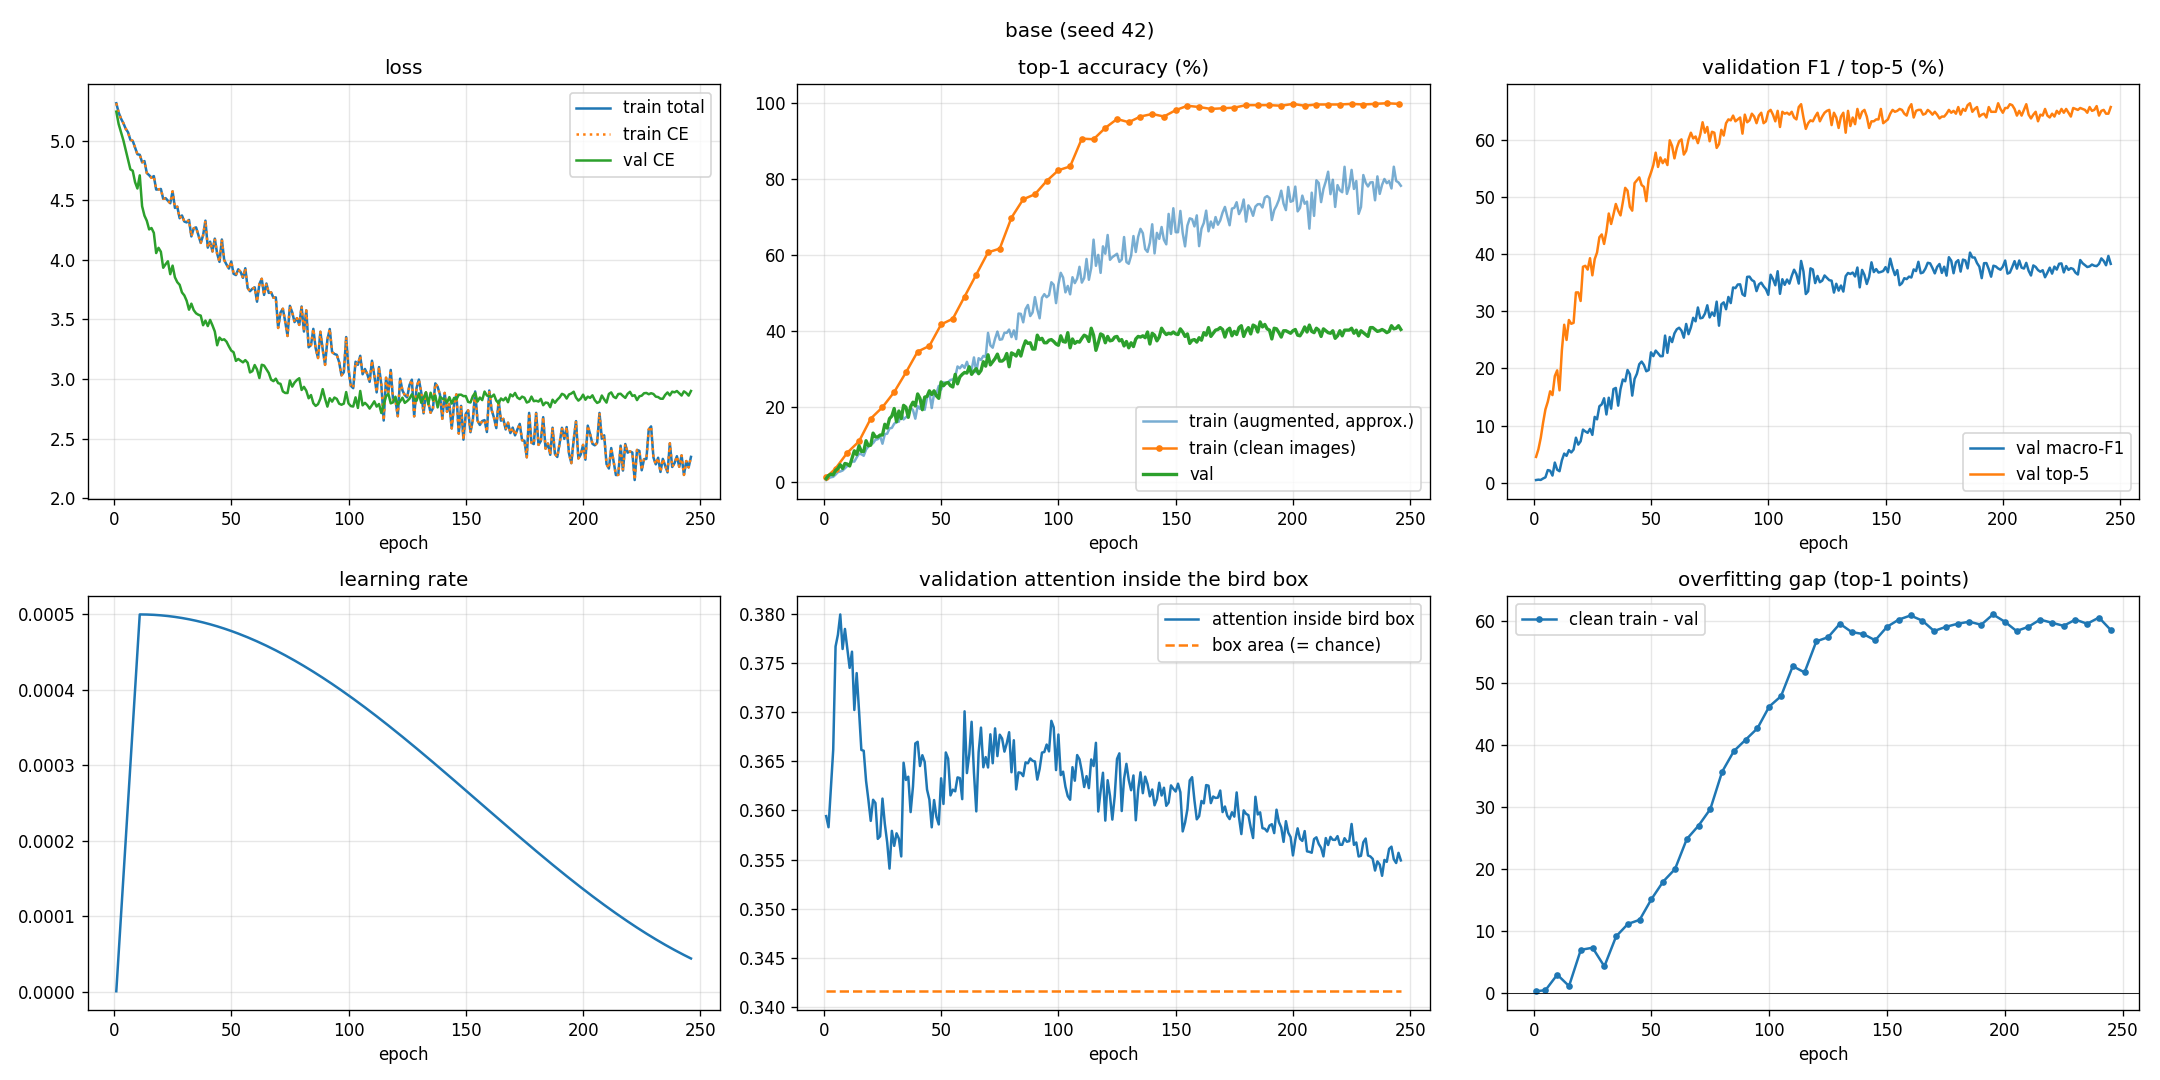

test_attention_gallery.png


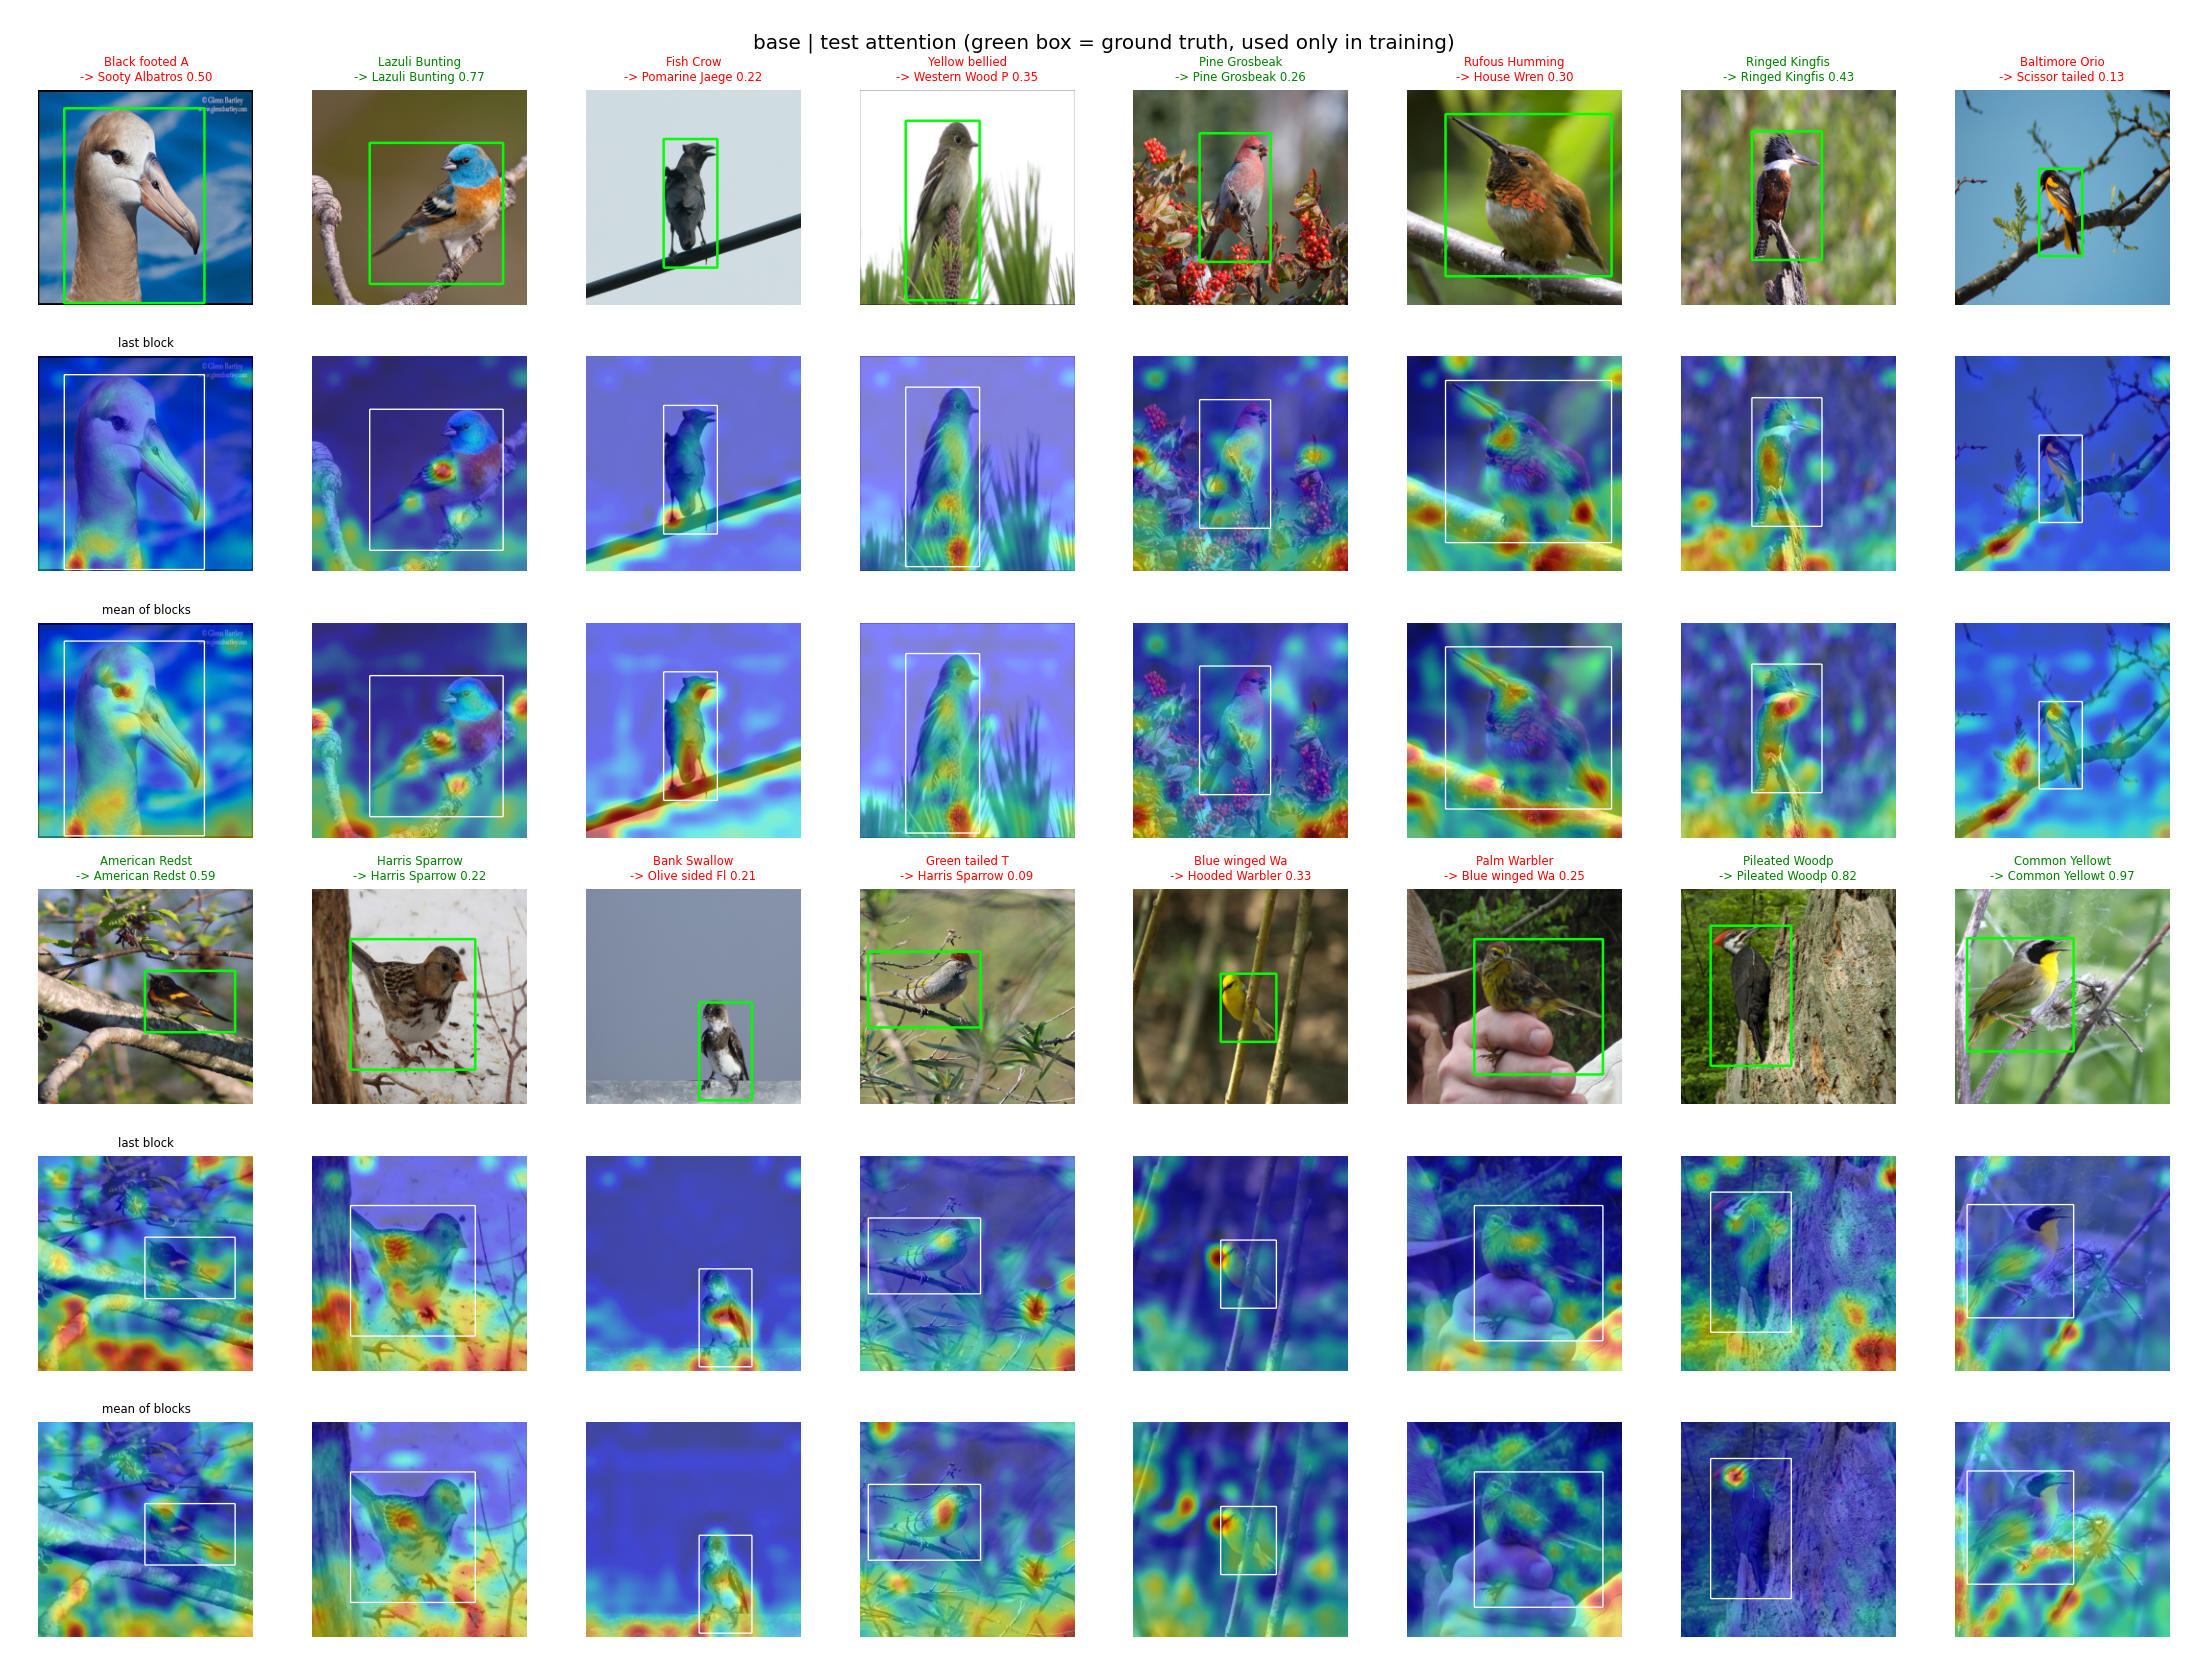

test_confusion_matrix.png


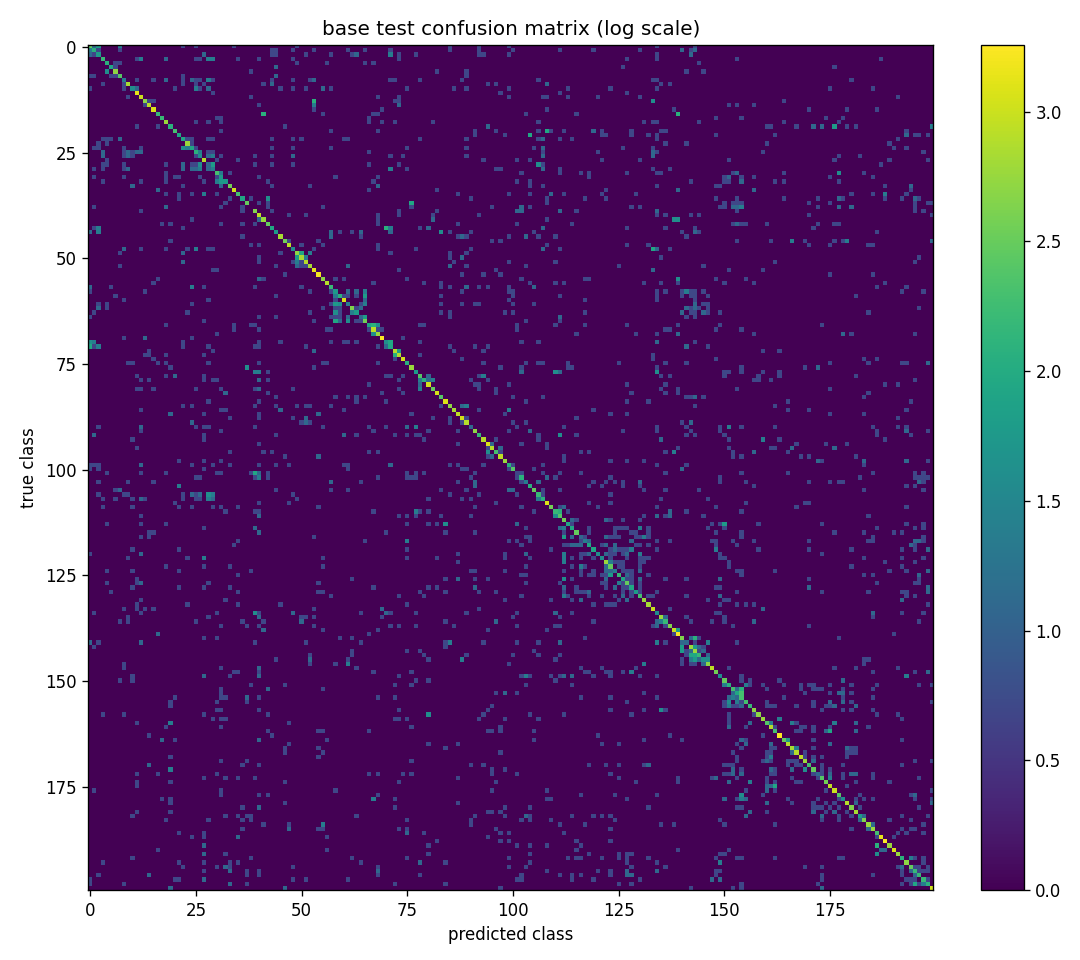

test_reliability.png


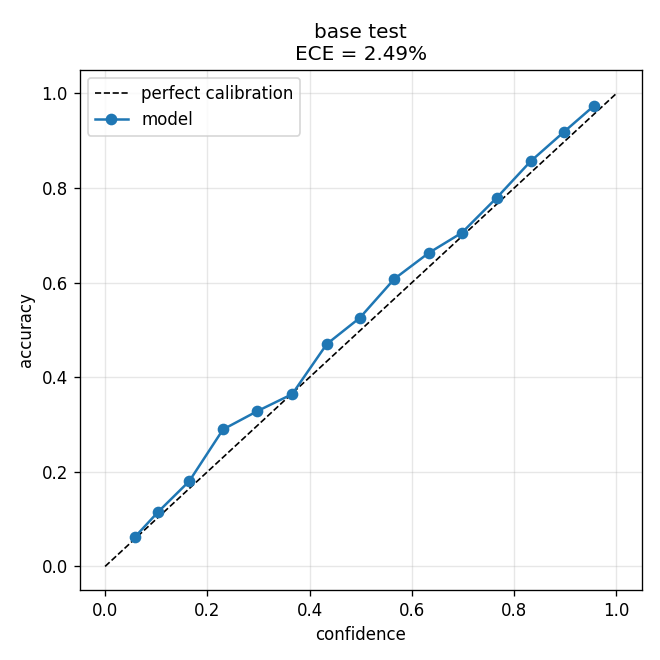

In [6]:
display(summarize_results(PATHS))
run_dir = Path(rows[-1]["run_dir"])
print("all files of the last run are in:", run_dir)
for name in ("curves.png", "test_attention_gallery.png", "test_confusion_matrix.png", "test_reliability.png"):
    if (run_dir / name).exists():
        print(name)
        display(show_image(filename=str(run_dir / name)))

## 6. Ablation suite (optional, long)

Runs several variants and writes `results/ablation_table.csv` / `.md` (mean +/- std over seeds).
Finished runs are skipped, so you can run this cell again after an interruption.
`base` = GvT-style anchor; `arch_x` = PatchVision-X architecture without regularisers; `full` = everything; `full-<x>` = leave one component out.

In [7]:
RUN_ABLATIONS = False
SUITE = ["base", "lfe", "multiscale", "arch_x", "arch_x+bbox", "arch_x+ema", "arch_x+cons", "arch_x+boxcrop", "full"]
if RUN_ABLATIONS:
    run_suite(SUITE, SEEDS, PATHS, MODEL_OVERRIDES, TRAIN_OVERRIDES, num_workers=NUM_WORKERS,
              step_print_every=STEP_PRINT_EVERY, resume=RESUME)
    display(summarize_results(PATHS))

## 7. Live monitor (read-only)

A running training cell blocks its notebook kernel, so run this from a **second notebook/kernel**
(or from a terminal: `python watch_training.py full 42`). It refreshes every 2 s with a progress bar for the current epoch
and a table of the latest epochs, and stops by itself when the run has finished. Interrupting it never affects the training.

In [8]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from patchvision.monitor import watch

watch(Path("results") / "base" / "seed42", interval=2.0, rows=15)     # change "base"/"seed42" for another run

PatchVision-X live monitor | results\base\seed42  |  19:44:10
epoch 246/300  [##############################] 100.0%  step 84/84
  loss 3.462 (ce 3.462, bbox 0.789, cons 0.0000/0.0000) | batch acc 50.0% | in-box 0.505 | lr 4.25e-05 | gnorm 3.38 | 729 img/s | GPU mem 4.81 GB
overall [#########################-----]  82.0%  246/300 epochs | 10.7 s/epoch | FINISHED

 epoch | train loss | val loss | val top-1 | raw top-1 | clean-train | gap | val top-5 | val F1 | in-box | lr        | time
----------------------------------------------------------------------------------------------------------------------
   232 |      2.340 |    2.849 |    38.50% |         - |           - |     - |    65.33% |  36.48 |  0.355 | 6.75e-05 |   10s
   233 |      2.221 |    2.836 |    40.83% |         - |           - |     - |    65.67% |  39.01 |  0.355 | 6.57e-05 |    9s
   234 |      2.331 |    2.835 |    40.83% |         - |           - |     - |    65.50% |  38.45 |  0.355 | 6.39e-05 |   10s
   235 |     